In [1]:
import geopandas as gpd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
import pandas as pd 
import polars as pl
import sys
sys.path.append("../src")  # Add path to where 'retail' package lives
import retail.retailfilter as rf # Correct import path
import retail.retailfilter_new as rfn
import utils.utils as ut  # Correct import path
data_proc = pl.read_parquet("new_data_test.parquet")

[nltk_data] Downloading package names to /home/ogoodwin/nltk_data...
[nltk_data]   Package names is already up-to-date!


In [2]:
print(len(data_proc))
data_proc = rfn.filter_foursquare(data_proc)
print(len(data_proc))

4129413
Filtered Foursquare data: 1650743 rows remaining.
1483685


In [3]:
data_proc=data_proc[["fsq_place_id", "unresolved_flags","name","address","locality","region","postcode","admin_region","post_town","po_box","country","date_created","date_refreshed","date_closed","fsq_category_labels","lat","lng"]]
#convert to pd
data_proc = data_proc.to_pandas()

array([[<Axes: title={'center': 'date_refreshed'}>]], dtype=object)

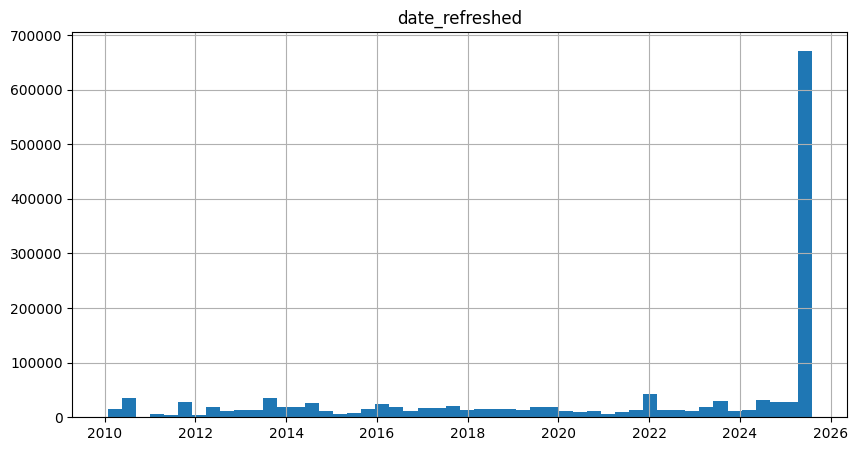

In [4]:

data_proc['date_refreshed'] = pd.to_datetime(data_proc['date_refreshed'])
data_proc.hist(bins=50, column='date_refreshed', figsize=(10, 5))

In [ ]:
#fraction before 2020

Frac removed:  0.29892141756548535


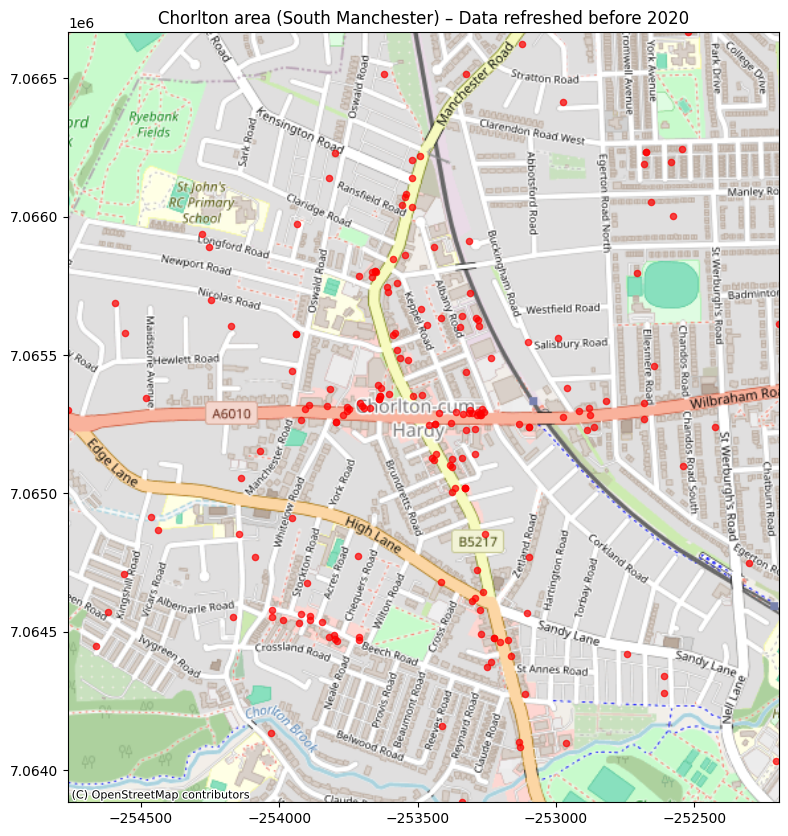

In [5]:
# sample of 50 located in south manchester
# using (min_lat, min_lon) = (53.420, -2.310)
# (max_lat, max_lon) = (53.450, -2.255)
south_manchester_mask = (
    (data_proc['lat'] >= 53.435) &
    (data_proc['lat'] <= 53.450) &
    (data_proc['lng'] >= -2.290) &
    (data_proc['lng'] <= -2.265)
)
date = '2019-01-01'
# south manchester refreshed before 2020
data_refreshed_before_2020_south_manchester = data_proc[
    south_manchester_mask & (data_proc['date_refreshed'] < date)
]

# south manchester refreshed after 2020
data_refreshed_after_2020_south_manchester = data_proc[
    south_manchester_mask & (data_proc['date_refreshed'] >= date)
]

#what frac are before 2020 vs after
print("Frac removed: ",data_refreshed_before_2020_south_manchester.shape[0] / (data_refreshed_after_2020_south_manchester.shape[0]+data_refreshed_before_2020_south_manchester.shape[0]))

# Convert DataFrame -> GeoDataFrame using lat/lng
gdf_before = gpd.GeoDataFrame(
    data_refreshed_before_2020_south_manchester,
    geometry=gpd.points_from_xy(
        data_refreshed_before_2020_south_manchester["lng"],
        data_refreshed_before_2020_south_manchester["lat"]
    ),
    crs="EPSG:4326"  # WGS84
)
#save to parquet
gdf_before.to_parquet("data_refreshed_before_2020_south_manchester.parquet")

gdf_after = gpd.GeoDataFrame(
    data_refreshed_after_2020_south_manchester,
    geometry=gpd.points_from_xy(
        data_refreshed_after_2020_south_manchester["lng"],
        data_refreshed_after_2020_south_manchester["lat"]
    ),
    crs="EPSG:4326"  # WGS84
)

gdf_after.to_parquet("data_refreshed_after_2020_south_manchester.parquet")
# Bounding box for Chorlton (approx)
chorlton_bbox = {
    "minx": -2.330,
    "maxx": -2.255,
    "miny": 53.420,
    "maxy": 53.450
}

# Clip to Chorlton bounding box
chorlton = gdf_before.cx[
    chorlton_bbox["minx"]:chorlton_bbox["maxx"],
    chorlton_bbox["miny"]:chorlton_bbox["maxy"]
]

# Reproject to Web Mercator for OSM
chorlton = chorlton.to_crs(epsg=3857)

# Plot
fig, ax = plt.subplots(figsize=(10, 10))
chorlton.plot(ax=ax, color="red", markersize=20, alpha=0.7)

# Add OSM basemap
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)

# Zoom into bbox
ax.set_xlim(chorlton.total_bounds[0], chorlton.total_bounds[2])
ax.set_ylim(chorlton.total_bounds[1], chorlton.total_bounds[3])

plt.title("Chorlton area (South Manchester) – Data refreshed before 2020")
plt.show()



In [ ]:
#save as geodf parquet
data_refreshed_before_2020_south_manchester.to_parquet("data_refreshed_before_2020_south_manchester.parquet")
data_refreshed_after_2020_south_manchester.to_parquet("data_refreshed_after_2020_south_manchester.parquet")
data_refreshed_before_2020_south_manchester_rand = data_refreshed_before_2020_south_manchester.sample(n=50, random_state=42)
data_refreshed_before_2020_south_manchester_rand

,fsq_place_id,unresolved_flags,name,address,locality,region,postcode,admin_region,post_town,po_box,country,date_created,date_refreshed,date_closed,fsq_category_labels,lat,lng
1088805,2f31fba93da642f7916d3fb3,[],Shake & Bakery,30a Manchester Rd,Manchester,Greater Manchester,M21 9PH,England,Manchester,None,GB,2014-09-25,2014-09-25,None,"[Dining and Drinking > Cafe, Coffee, and Tea H...",53.443818,-2.277899
162611,5e9dd6e437324586f30cda5b,[],LQ Photography,"16 Lyndhurst Ct, Whitelow Rd",Manchester,Greater Manchester,M21 9RS,England,Manchester,None,GB,2014-06-13,2014-06-13,None,[Business and Professional Services > Photogra...,53.440578,-2.281291
1247725,be73abe4b5ee49b63304174e,[],Desi Roots,483 Barlow Moor Rd,Manchester,Greater Manchester,M21 8AG,England,Manchester,None,GB,2016-05-13,2016-05-13,None,[Dining and Drinking > Restaurant > Fast Food ...,53.438246,-2.274742
805312,b607c0c21189453704145ff5,[],Al Hermain Cash N Carry,225 Clarendon Rd,Manchester,Greater Manchester,M16 0AY,England,Manchester,None,GB,2016-08-20,2016-08-20,None,[Retail > Warehouse or Wholesale Store],53.447640,-2.269820
530183,53e34e4b498e38b5df5e1aaf,[],loca Jewellery And Art Gallery,None,None,None,None,None,None,None,GB,2014-08-07,2014-08-07,None,[Retail > Fashion Retail > Jewelry Store],53.435077,-2.275790
1231480,18d0b6b85fdc400f4adc66fb,[],Northern Renaissance Instruments,6 Needham Ave,Manchester,Greater Manchester,M21 8AA,England,Manchester,None,GB,2012-05-29,2012-05-29,None,"[Arts and Entertainment, Business and Professi...",53.441807,-2.275374
438584,4dc594397d8b14fb462e6369,[],Waters Edge,Manchester Road,Manchester,Greater Manchester,M21 9JG,England,None,None,GB,2011-05-07,2012-05-30,None,[Arts and Entertainment > Performing Arts Venu...,53.441863,-2.282337
158704,7e6e1b92356b4be495877bc3,[],Motorland,59-61 Manchester Rd,Manchester,Greater Manchester,M21 9PW,England,Manchester,None,GB,2012-05-29,2012-05-29,None,[Retail > Automotive Retail > Car Parts and Ac...,53.445336,-2.278613
936984,4f2f16d681d940c814ecaf7d,[],One Stop Bargains,162 Manchester Rd,Manchester,Greater Manchester,M16 0DZ,England,Manchester,None,GB,2014-11-22,2014-11-22,None,[Retail > Discount Store],53.449722,-2.273858
927939,4af2da20f964a520c0e821e3,[],Elliotts,Manchester Road,Manchester,UK,None,England,None,None,GB,2009-11-05,2014-10-11,None,[Dining and Drinking > Restaurant > Sandwich S...,53.447138,-2.277415


Frac removed (Allerton):  0.24734982332155478


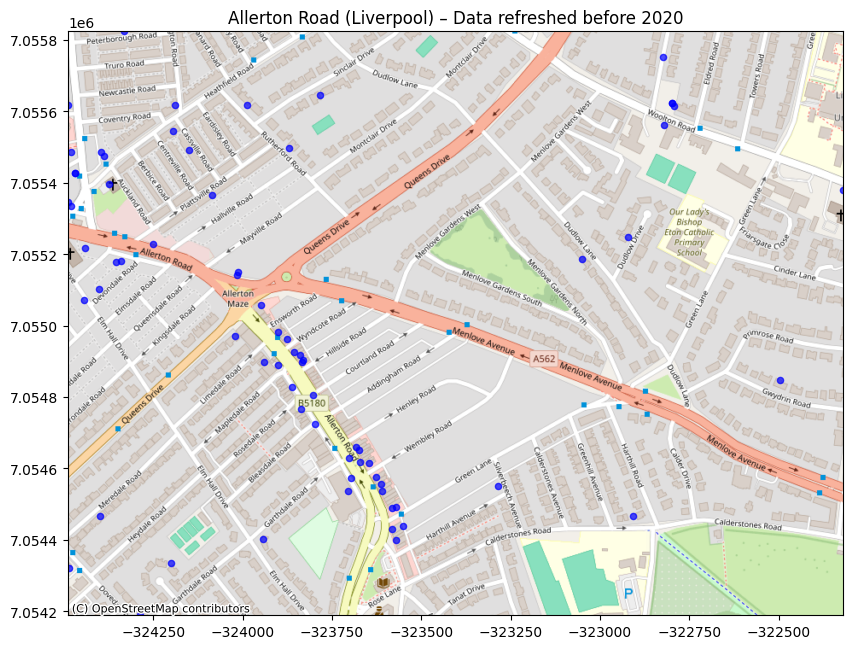

In [23]:
# sample around Allerton Road, Liverpool
# Approx bounding box (tight around Allerton Road)
allerton_bbox = {
    "minx": -2.915,   # west
    "maxx": -2.892,   # east
    "miny": 53.382,   # south
    "maxy": 53.392    # north
}

# Allerton Road mask
allerton_mask = (
    (data_proc['lat'] >= allerton_bbox["miny"]) &
    (data_proc['lat'] <= allerton_bbox["maxy"]) &
    (data_proc['lng'] >= allerton_bbox["minx"]) &
    (data_proc['lng'] <= allerton_bbox["maxx"])
)

date = '2019-01-01'

# Allerton refreshed before 2020
data_refreshed_before_2020_allerton = data_proc[
    allerton_mask & (data_proc['date_refreshed'] < date)
]

# Allerton refreshed after 2020
data_refreshed_after_2020_allerton = data_proc[
    allerton_mask & (data_proc['date_refreshed'] >= date)
]

# What fraction removed
print("Frac removed (Allerton): ",
      data_refreshed_before_2020_allerton.shape[0] /
      (data_refreshed_after_2020_allerton.shape[0] +
       data_refreshed_before_2020_allerton.shape[0]))

# Convert DataFrame -> GeoDataFrame
gdf_before_allerton = gpd.GeoDataFrame(
    data_refreshed_before_2020_allerton,
    geometry=gpd.points_from_xy(
        data_refreshed_before_2020_allerton["lng"],
        data_refreshed_before_2020_allerton["lat"]
    ),
    crs="EPSG:4326"
)
gdf_before_allerton.to_parquet("data_refreshed_before_2020_allerton.parquet")

gdf_after_allerton = gpd.GeoDataFrame(
    data_refreshed_after_2020_allerton,
    geometry=gpd.points_from_xy(
        data_refreshed_after_2020_allerton["lng"],
        data_refreshed_after_2020_allerton["lat"]
    ),
    crs="EPSG:4326"
)
gdf_after_allerton.to_parquet("data_refreshed_after_2020_allerton.parquet")

# Clip to Allerton Road bounding box
allerton = gdf_before_allerton.cx[
    allerton_bbox["minx"]:allerton_bbox["maxx"],
    allerton_bbox["miny"]:allerton_bbox["maxy"]
]

# Reproject to Web Mercator for OSM
allerton = allerton.to_crs(epsg=3857)

# Plot
fig, ax = plt.subplots(figsize=(10, 10))
allerton.plot(ax=ax, color="blue", markersize=20, alpha=0.7)

# Add OSM basemap
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)

# Zoom into bbox
ax.set_xlim(allerton.total_bounds[0], allerton.total_bounds[2])
ax.set_ylim(allerton.total_bounds[1], allerton.total_bounds[3])

plt.title("Allerton Road (Liverpool) – Data refreshed before 2020")
plt.show()


In [24]:
# Save as GeoDataFrame parquet
data_refreshed_before_2020_allerton.to_parquet("data_refreshed_before_2020_allerton.parquet")
data_refreshed_after_2020_allerton.to_parquet("data_refreshed_after_2020_allerton.parquet")

# Random sample of 50 from "before 2020"
data_refreshed_before_2020_allerton_rand = data_refreshed_before_2020_allerton.sample(
    n=50, random_state=42
)

data_refreshed_before_2020_allerton_rand


,fsq_place_id,unresolved_flags,name,address,locality,region,postcode,admin_region,post_town,po_box,country,date_created,date_refreshed,date_closed,fsq_category_labels,lat,lng
523276,00ccc2d9b887470d653f7d2d,[],Verdant,149-151 Allerton Rd,Liverpool,Merseyside,L18 2DD,England,Liverpool,None,GB,2017-10-30,2017-10-30,None,[Dining and Drinking > Restaurant],53.384772,-2.906792
22029,4e74b4e6b993a71aa3604d3e,[],Alibaba,97 Allerton Roaf,Liverpool,Merseyside,L182 4DD,England,None,None,GB,2011-09-17,2018-11-23,None,[Dining and Drinking > Restaurant > Middle Eas...,53.387342,-2.910725
1032698,4c6940053bad2d7fe14cafee,[],Odd Bins,None,Liverpool,Liverpool,None,England,None,None,GB,2010-08-16,2016-01-21,None,[Retail > Food and Beverage Retail > Wine Store],53.386035,-2.908725
100903,0fbc2bcc851f4e98864c455b,[],Pure Dental,43 Allerton Rd,Liverpool,Merseyside,L18 2DA,England,Liverpool,None,GB,2012-12-27,2012-12-27,None,[Health and Medicine > Dentist],53.386955,-2.909052
1081163,738f873764ee41bcfe1cc076,[],Liverpool Irish Festival Society Company,5 Rutherford Rd,Liverpool,Merseyside,L18 0HJ,England,Liverpool,None,GB,2013-07-16,2013-07-16,None,[Arts and Entertainment],53.390805,-2.910424
392518,854afbc55bd544aef9e2323b,[],Protime Tech,16 Harthill Rd,Liverpool,Merseyside,L18 6HU,England,Liverpool,None,GB,2017-03-18,2017-03-18,None,[Retail],53.384645,-2.900730
186557,566c6dce498e91369f4148fd,[],Bethel Welsh Presbytarian Church,Heathfield Road,Liverpool,Merseyside,L17 1AF,England,None,None,GB,2015-12-12,2018-04-11,None,[Community and Government > Spiritual Center >...,53.390132,-2.911879
736998,4f48c554e4b0cf7a069cee9c,[],SMBeauty clinic,None,None,None,None,None,None,None,GB,2012-02-25,2012-02-25,None,[Business and Professional Services > Health a...,53.391528,-2.899973
974599,a770167b2e894f67d5eb6ac8,[],Abensons Solicitors,102 Allerton Rd,Liverpool,Merseyside,L18 2DG,England,Liverpool,None,GB,2010-05-24,2010-05-24,None,[Business and Professional Services > Legal Se...,53.386952,-2.910013
266118,56eead7e498eaa1cd83dda29,[],The Corner Room,None,None,Merseyside,None,England,None,None,GB,2016-03-20,2017-08-19,None,"[Dining and Drinking > Cafe, Coffee, and Tea H...",53.385439,-2.907357


In [34]:
#find places called memos?
# data_proc[data_proc['name'].str.contains("memo's", case=False)]

#find places with address 149-151 Allerton Road
data_proc[data_proc['address'].str.contains("149-151 Allerton", case=False, na= False)]

,fsq_place_id,unresolved_flags,name,address,locality,region,postcode,admin_region,post_town,po_box,country,date_created,date_refreshed,date_closed,fsq_category_labels,lat,lng
523276,00ccc2d9b887470d653f7d2d,[],Verdant,149-151 Allerton Rd,Liverpool,Merseyside,L18 2DD,England,Liverpool,None,GB,2017-10-30,2017-10-30,None,[Dining and Drinking > Restaurant],53.384772,-2.906792


In [26]:
#what frac of data has an unresolved flag (non empty list)
data_proc['unresolved_flags'].apply(lambda x: len(x) > 0).mean()

0.001802383243662366

In [27]:
#filter for unresolved flags
data_proc[data_proc['unresolved_flags'].apply(lambda x: len(x) > 0)]

,fsq_place_id,unresolved_flags,name,address,locality,region,postcode,admin_region,post_town,po_box,country,date_created,date_refreshed,date_closed,fsq_category_labels
1382,534808d7498ef3608ae7434b,[doesnt_exist],Miracle Span Steel Buildings,Units 4&5 South Road Ind Estate,"North Somercotes, Louth",Lincs,LN11 7PT,England,None,None,GB,2014-04-11,2014-05-22,None,[Business and Professional Services > Warehouse]
2131,4c8a3721e51e6dcb19c066de,[duplicate],Smugglers Cave,None,None,None,None,England,None,None,GB,2010-09-10,2015-10-01,None,[Retail > Gift Store]
2448,5200e16b498e022ef638b8e2,[duplicate],The Baguette Shop,None,None,Norfolk,None,England,None,None,GB,2013-08-06,2022-11-21,None,[Dining and Drinking > Restaurant > Sandwich S...
2924,56ec2a26c9854d40f3c8440e,[duplicate],Post Office,10-11 High St,Cromer,Norfolk,NR27 9HG,England,Cromer,None,GB,2017-06-24,2025-05-30,None,[Community and Government > Government Buildin...
3578,4e636640aeb736031553558a,[duplicate],SPAR,None,None,Norfolk,None,England,None,None,GB,2011-09-04,2022-05-15,None,"[Retail > Convenience Store, Business and Prof..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4684111,4c7d40ccd598a093ee4bc262,[duplicate],Gurkha Kitchen,None,None,Shetland,None,Scotland,None,None,GB,2010-08-31,2022-07-03,None,[Dining and Drinking > Restaurant > Indian Res...
4684307,50153923e4b0c79e489d5f79,[closed],Da Muckle Cafe,Clickimin,Lerwick,Shetland Islands,ZE1 0PJ,Scotland,None,None,GB,2012-07-29,2013-08-26,None,"[Dining and Drinking > Cafe, Coffee, and Tea H..."
4684666,5103b309e4b0cc17c2401a9c,[duplicate],royal bank of scotland,commercial street,lerwick,Lerwick,ZE1 0DL,Scotland,None,None,GB,2013-01-26,2024-08-30,None,[Business and Professional Services > Financia...
4684667,5103b309e4b0cc17c2401a9c,[duplicate],royal bank of scotland,commercial street,lerwick,Lerwick,ZE1 0DL,Scotland,None,None,GB,2013-01-26,2024-08-30,None,[Business and Professional Services > Financia...
